# HostWise - Track A: Data Understanding (five cities)

**Cities:** Barcelona, London, Madrid, Paris, Rome. New York was removed by team decision; the instructor required all Day 1 analyses to be rerun on the five-city data. This notebook loads the five-city file `hostwise_5cities.csv` directly and checks that it contains exactly these five cities.

**Goal:** understand the structure of the dataset, the meaning and format of the core columns, and which columns are usable, unusable or leaking the target - before any cleaning or modelling.

**Notebook guide**

| Section | Question |
|---|---|
| A1 | How large is each analysis population, per city? |
| A2 | What do the core numerical columns contain? |
| A3 | What do the core categorical columns contain? |
| A4 | Which columns store information in a format that must be parsed? |
| A5 | Which columns are the target, leak the target, or carry no information? |
| A6 | Data dictionary |

Data-quality checks (duplicates, invalid values, stay length, missingness patterns, outliers) are in the Track C notebook. Relationships with price are in the Track B notebook.

## 0. Setup

The setup cells are identical in every HostWise notebook, so all tracks use the same data and the same population definitions.

| Name | Definition |
|---|---|
| `df_all` | All listings in `hostwise_5cities.csv` (five cities) |
| `df_active` | `source == "city scrape"`: listings present in the current scrape |
| `df_priced` | `df_active` with a parseable price |
| `df_scope` | `df_priced` with `minimum_nights <= 29` (short-term scope, pending team approval) |

Conventions: the parsed price is `price_num` and the log target is `log_price` (`log1p`, inverse `expm1`). Prices are in local currency (London GBP, other cities EUR).

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
DATA_CANDIDATES = [
    Path("hostwise_5cities.csv"),
    Path("hostwise_5cities.csv"),
    Path("hostwise_5cities.csv"),
    Path("Airbnb/hostwise_5cities.csv"),
]
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

CITY_ORDER = ["london", "paris", "rome", "madrid", "barcelona"]
CURRENCY = {"london": "GBP", "paris": "EUR", "rome": "EUR",
            "madrid": "EUR", "barcelona": "EUR"}

MAX_SHORT_STAY_NIGHTS = 29   # short-term scope threshold (pending team approval)
PRICE_FLOOR = 10             # data-validity floor in local currency (pending team approval)
FENCE_K = 3                  # log-IQR fence multiplier for price outliers

In [3]:
data_file = next((path for path in DATA_CANDIDATES if path.exists()), None)
if data_file is None:
    raise FileNotFoundError("hostwise_5cities.csv not found - update DATA_CANDIDATES.")

df_all = pd.read_csv(data_file, low_memory=False)

# Validation: the file must contain exactly the five project cities (no New York).
assert set(df_all["city"].unique()) == set(CITY_ORDER), sorted(df_all["city"].unique())
print(f"df_all: {df_all.shape[0]:,} listings x {df_all.shape[1]} columns")
print(df_all["city"].value_counts().reindex(CITY_ORDER).to_string())

df_all: 245,402 listings x 92 columns
city
london       92638
paris        77679
rome         37084
madrid       22708
barcelona    15293


In [4]:
# Derived target columns. The original `price` column is never modified.
df_all["price_num"] = pd.to_numeric(
    df_all["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)
df_all["log_price"] = np.log1p(df_all["price_num"])

# Analysis populations (identical definitions in every HostWise notebook)
df_active = df_all[df_all["source"] == "city scrape"]
df_priced = df_active[df_active["price_num"].notna()]
df_scope = df_priced[df_priced["minimum_nights"] <= MAX_SHORT_STAY_NIGHTS]

print(f"df_active: {len(df_active):,} | df_priced: {len(df_priced):,} | df_scope: {len(df_scope):,}")

df_active: 174,922 | df_priced: 168,725 | df_scope: 153,812


## A1. Dataset structure and analysis populations

**Research question:** How many listings does each city contribute to each analysis population, and how much data is lost at each scoping step?

**Purpose:** Every later statistic depends on the population it is computed on. Earlier versions of the Day 1 notebooks used three different populations without saying so (for example, `bathrooms` was 6.6% missing in one notebook and 33.4% in another). Making the populations explicit removes that confusion and shows how balanced the modelling data is across cities.

In [5]:
column_types = df_all.drop(columns=["price_num", "log_price"]).dtypes.astype(str).value_counts()
column_types.rename("columns").to_frame()

,columns
float64,42
object,31
int64,18


In [6]:
populations = {
    "df_all": df_all,
    "df_active": df_active,
    "df_priced": df_priced,
    "df_scope": df_scope,
}

population_counts = (
    pd.DataFrame({name: frame["city"].value_counts() for name, frame in populations.items()})
    .reindex(CITY_ORDER)
)
population_counts.loc["total"] = population_counts.sum()
population_counts

,df_all,df_active,df_priced,df_scope
city,,,,
london,92638,61587,59345,58810
paris,77679,48140,45215,39369
rome,37084,33612,33136,31275
madrid,22708,18548,18263,16257
barcelona,15293,13035,12766,8101
total,245402,174922,168725,153812


In [7]:
retention = pd.DataFrame({
    "df_all": population_counts.loc[CITY_ORDER, "df_all"],
    "df_scope": population_counts.loc[CITY_ORDER, "df_scope"],
})
retention["retained_%"] = retention["df_scope"] / retention["df_all"] * 100
retention["share_of_scope_%"] = retention["df_scope"] / retention["df_scope"].sum() * 100
retention

,df_all,df_scope,retained_%,share_of_scope_%
city,,,,
london,92638,58810,63.48,38.23
paris,77679,39369,50.68,25.60
rome,37084,31275,84.34,20.33
madrid,22708,16257,71.59,10.57
barcelona,15293,8101,52.97,5.27


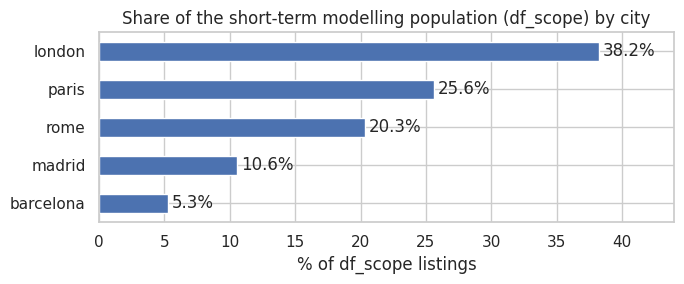

In [8]:
scope_share = retention["share_of_scope_%"].sort_values()

ax = scope_share.plot(kind="barh", figsize=(7, 3), color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Share of the short-term modelling population (df_scope) by city",
       xlabel="% of df_scope listings", ylabel="")
ax.set_xlim(0, scope_share.max() * 1.15)
plt.tight_layout()
plt.savefig(FIG_DIR / "a1_scope_share_by_city.png", dpi=150)
plt.show()

### Findings

- **Columns:** 91 original columns - 42 `float64`, 18 `int64`, 31 `object`. The 12 fully empty columns are stored as `float64` because they contain only missing values (A5).
- **Population sizes:** `df_all` 245,402 -> `df_active` 174,922 -> `df_priced` 168,725 -> `df_scope` 153,812.
- **City imbalance:** London (92,638) and Paris (77,679) are 69.4% of `df_all`. In `df_scope`, London is 38.2%, Paris 25.6%, Rome 20.3%, Madrid 10.6% and Barcelona 5.3%.
- **Retention from `df_all` to `df_scope` differs strongly by city:** Rome 84.3%, Madrid 71.6%, London 63.5%, Barcelona 53.0%, Paris 50.7%. Paris loses the most because it has the highest share of listings without a price (37.7%, see Track C) plus 13.6% long-stay listings. Barcelona loses 36.7% of its active listings to the long-stay filter.
- Only 6,197 active listings (3.5%) have no price.
- **Imbalance in the modelling population:** London has 7.3 times as many `df_scope` listings as Barcelona (58,810 vs 8,101). A metric pooled over all listings would therefore be driven mostly by London and Paris (63.8% of `df_scope` together).

### Conclusion

- **Confirmed:** the five cities are strongly imbalanced, both in raw size and in how much of each city survives the scoping steps.
- **Recommendation:** report model performance **separately for each city**, so that a good overall score cannot hide a weak city.
- **Proposed evaluation strategy (requires team approval):** compare models with an equal-weight average across cities (macro-average) instead of a pooled average over all listings, so that London and Paris do not dominate model selection.
- Barcelona contributes only ~8.1k scope listings, so its test-set error estimates will be the least stable. This is a limitation to state in the presentation.
- **Pending team decision:** the `minimum_nights <= 29` scope. If it is not approved, `df_scope` counts change.

## A2. Numerical core columns

**Research question:** What are the real ranges, missing shares and distributions of the core numerical features in the active listings?

**Purpose:** A data dictionary written from assumptions is wrong in exactly the places that matter. This profile reveals implausible values, placeholders and structural missingness that decide the Day 2 preprocessing.

In [9]:
NUMERIC_CORE = [
    "accommodates", "bedrooms", "beds", "bathrooms",
    "minimum_nights", "maximum_nights",
    "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "review_scores_location",
    "host_listings_count", "calculated_host_listings_count", "hosts_time_as_host_years",
    "availability_365", "estimated_occupancy_l365d",
]

numeric_profile = df_active[NUMERIC_CORE].describe(percentiles=[0.01, 0.5, 0.99]).T
numeric_profile.insert(0, "missing_%", df_active[NUMERIC_CORE].isna().mean() * 100)
numeric_profile.drop(columns="count")

,missing_%,mean,std,min,1%,50%,99%,max
accommodates,0.00,3.59,2.11,1.00,1.00,3.00,11.00,16.00
bedrooms,17.99,1.68,1.05,0.00,1.00,1.00,5.00,50.00
beds,2.26,2.11,1.64,1.00,1.00,2.00,7.00,167.00
bathrooms,6.59,1.33,0.72,0.50,1.00,1.00,4.00,42.00
minimum_nights,0.01,4.98,8.70,1.00,1.00,2.00,32.00,95.00
maximum_nights,0.01,"150,844.03","17,831,159.75",2.00,7.00,365.00,"1,125.00","2,147,483,647.00"
number_of_reviews,0.00,47.05,91.92,0.00,0.00,12.00,448.00,"4,589.00"
reviews_per_month,18.59,1.54,1.73,0.00,0.03,1.00,7.00,100.58
review_scores_rating,18.59,4.70,0.44,0.00,3.00,4.82,5.00,5.00
review_scores_location,18.59,4.77,0.35,0.00,3.33,4.87,5.00,5.00


### Findings (active listings, n = 174,922)

- **Size features:** `accommodates` is complete and plausible (1-16, median 3). `bedrooms` is 18.0% missing, with min 0 (studios) and an implausible max of 50. `beds` is 2.3% missing with max 167. `bathrooms` is 6.6% missing with max 42.
- **Stay limits:** `minimum_nights` has median 2, p99 32 and max 95. `maximum_nights` has max 2,147,483,647, the largest 32-bit integer - a placeholder, not a real value.
- **Reviews:** `number_of_reviews` has median 12 and max 4,589. `reviews_per_month` and `review_scores_*` are 18.6% missing. `review_scores_rating` has median 4.82 and p1 3.00 - a strong ceiling effect.
- **Hosts:** `calculated_host_listings_count` has median 3, mean 27.28 and max 754, a heavy right tail from professional operators. `host_listings_count` (Airbnb-wide) reaches 5,978.
- **Demand columns:** `availability_365` has median 243; `estimated_occupancy_l365d` is capped at 255.

### Conclusion

- **Confirmed:** `bedrooms`, `beds` and `bathrooms` contain implausible maxima. **Recommendation to investigate on Day 2:** whether to cap, flag or keep them (counts per city in Track C, section C6).
- **Confirmed:** `maximum_nights` contains a placeholder value. **Recommendation to validate:** remove it or cap it, since it has little pricing meaning.
- **Hypothesis:** the review-score ceiling suggests a weak signal; Track B (section B9) tests this directly.
- **Recommendation to validate:** prefer `calculated_host_listings_count` (within-city) over `host_listings_count` (Airbnb-wide) as a host-type feature.

## A3. Categorical core columns

**Research question:** How many categories does each core categorical feature have, how complete is it, and how dominant is its most common value?

**Purpose:** Cardinality and dominance decide the encoding strategy. A near-constant column carries no information; a high-cardinality column needs grouping or target encoding.

In [10]:
def summarize_categorical(series: pd.Series) -> pd.Series:
    counts = series.value_counts()
    return pd.Series({
        "missing_%": round(series.isna().mean() * 100, 1),
        "n_unique": series.nunique(),
        "top_value": counts.index[0],
        "top_share_%": round(counts.iloc[0] / series.notna().sum() * 100, 1),
    })

In [11]:
CATEGORICAL_CORE = [
    "room_type", "property_type", "neighbourhood_cleansed", "neighbourhood_group_cleansed",
    "bathrooms_text", "host_is_superhost", "host_identity_verified",
    "has_availability", "license",
]

categorical_profile = df_active[CATEGORICAL_CORE].apply(summarize_categorical).T
categorical_profile

,missing_%,n_unique,top_value,top_share_%
room_type,0.00,4,Entire home/apt,77.00
property_type,0.00,100,Entire rental unit,60.80
neighbourhood_cleansed,0.00,265,I Centro Storico,9.90
neighbourhood_group_cleansed,81.90,31,Centro,25.00
bathrooms_text,0.10,56,1 bath,54.30
host_is_superhost,0.00,2,f,70.50
host_identity_verified,0.00,2,t,98.70
has_availability,1.00,2,t,99.30
license,43.20,79371,"Available with a mobility lease only (""bail mobilité"")",6.20


In [12]:
df_active["room_type"].value_counts().rename("listings").to_frame()

,listings
room_type,
Entire home/apt,134741
Private room,38775
Hotel room,785
Shared room,621


### Findings (active listings)

- **`room_type`:** 4 categories. Entire home/apt 134,741 (77.0%), Private room 38,775, Hotel room 785, Shared room 621.
- **`property_type`:** 100 categories; the most common is "Entire rental unit" (106,351 listings).
- **`neighbourhood_cleansed`:** 265 official neighbourhoods across five cities; the largest is "I Centro Storico" (Rome, 17,231 listings).
- **`neighbourhood_group_cleansed`:** 81.9% missing, 31 groups. Only some cities provide district groups.
- **`bathrooms_text`:** 0.1% missing with 56 distinct values - far more complete than numeric `bathrooms` (6.6% missing).
- **`host_is_superhost`:** 51,660 superhosts (29.5%).
- **`host_identity_verified`:** 172,730 of 174,922 are "t" (98.7%) - nearly constant.
- **`has_availability`:** 1.0% missing; 172,037 "t" vs 1,155 "f" (99.3% "t") - nearly constant.
- **`license`:** 43.2% missing; the most frequent value is "Available with a mobility lease only (bail mobilite)" (6,195 listings).

### Conclusion

- `room_type` is complete and has only 4 values, so it is expected to be a core feature. Hotel and Shared rooms are small segments (<1% each); whether to keep them is a pending scope decision.
- **Confirmed:** `property_type` has 100 values, many of them rare. **Recommendation to investigate on Day 2:** group it into a small number of categories, and keep the grouping only if it preserves most of the price information (tested in Track B, section B5).
- **Confirmed:** `host_identity_verified` and `has_availability` are near-constant. **Recommendation to validate:** remove them from the features.
- **Confirmed:** `neighbourhood_group_cleansed` is 81.9% missing. **Recommendation to validate:** do not use it as a feature.

## A4. Columns with special formats

**Research question:** Which columns store information in a format that must be parsed before use, and what does that format contain?

**Purpose:** Numbers hidden in text and lists stored as strings cannot be used by a model directly. Understanding the format now determines the Day 2 parsing logic.

### A4.1 `bathrooms_text`

In [13]:
df_active["bathrooms_text"].value_counts().head(15).rename("listings").to_frame()

,listings
bathrooms_text,
1 bath,94798
2 baths,25063
1 private bath,15817
1 shared bath,12193
1.5 baths,8315
3 baths,3736
2.5 baths,3333
1.5 shared baths,2071
2 shared baths,2031


**Findings:** the text encodes three pieces of information:
- a **count**: "1 bath" 94,798; "2 baths" 25,063; "1.5 baths" 8,315;
- a **privacy type**: "private" ("1 private bath" 15,817), "shared" ("1 shared bath" 12,193; "2 shared baths" 2,031; "1.5 shared baths" 2,071), or not stated ("1 bath");
- **half-baths without a number**: "Shared half-bath" 712; "Half-bath" 481.

"0 baths" (1,362) and "0 shared baths" (837) also occur.

**Can missing `bathrooms` values be recovered from `bathrooms_text`?** The cells below parse the count from the text (a half-bath without a number counts as 0.5) and count, per population, how many missing `bathrooms` values have a usable count in `bathrooms_text`. The earlier team figures (12,839 missing / 12,646 recoverable / 193 not recoverable) came from the six-city data and are replaced by this table.

In [14]:
def parse_bath_count(bath_text: pd.Series) -> pd.Series:
    text = bath_text.str.lower()
    count = text.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    is_half_bath = text.str.contains("half-bath", na=False) & count.isna()
    return count.mask(is_half_bath, 0.5)

In [15]:
def bathroom_recovery(frame: pd.DataFrame) -> pd.Series:
    bathrooms_missing = frame["bathrooms"].isna()
    parsed_count = parse_bath_count(frame["bathrooms_text"])
    return pd.Series({
        "bathrooms missing": bathrooms_missing.sum(),
        "of which bathrooms_text present": (bathrooms_missing & frame["bathrooms_text"].notna()).sum(),
        "of which count recoverable from text": (bathrooms_missing & parsed_count.notna()).sum(),
        "still missing after using text": (bathrooms_missing & parsed_count.isna()).sum(),
    })


pd.DataFrame({name: bathroom_recovery(frame) for name, frame in
              {"df_all": df_all, "df_active": df_active, "df_scope": df_scope}.items()})

,df_all,df_active,df_scope
bathrooms missing,82005,11525,9762
of which bathrooms_text present,81801,11359,9607
of which count recoverable from text,81801,11359,9607
still missing after using text,204,166,155


**Findings:**
- **Confirmed (five-city data):** `bathrooms` is missing for 82,005 of 245,402 listings in `df_all` (33.42%) and for 11,525 of 174,922 active listings (6.6%). `bathrooms_text` is missing for only 247 listings in `df_all` (0.10%).
- The `previous scrape` rows account for 70,480 of the 82,005 missing values in `df_all` (Track C, C2), so most of the missingness disappears once the population is restricted to active listings.

> **Pending execution:** record the recovery table above, especially the `df_active` and `df_scope` columns. The "still missing after using text" row is the number of listings for which no bathroom count is available from either column.

**Conclusion:**
- **Recommendation to investigate on Day 2:** derive **two separate features** from `bathrooms_text`: `bath_count` (numeric; half-bath = 0.5) and `bath_privacy` (private / shared / not stated). They are kept separate because a shared bathroom is a different product from a private one with the same count.
- Listings with no count in either column stay missing at this stage; how to fill them is a Day 2 decision. **No "one bathroom per bedroom" rule is assumed:** nothing in the data supports a fixed bedroom-to-bathroom ratio, and `bedrooms` is itself 18.0% missing among active listings.
- "0 baths" for entire homes is investigated in Track C (section C6) before deciding whether it means "missing".

### A4.2 `amenities`

In [16]:
def parse_amenities(text):
    try:
        return json.loads(text)
    except (TypeError, ValueError):
        return None


amenity_lists = df_active["amenities"].map(parse_amenities)
print(f"Amenity strings parsed as JSON lists: {amenity_lists.notna().mean() * 100:.2f}%")

Amenity strings parsed as JSON lists: 100.00%


In [17]:
amenity_lists.dropna().iloc[0][:15]

['Essentials',
 'Other induction stove',
 'Smoke alarm',
 'Cooking basics',
 'Shower gel',
 'Dishes and silverware',
 'Hangers',
 'Toaster',
 'Dining table',
 'Coffee',
 'Wifi',
 'Room-darkening shades',
 'Iron',
 'Pack ’n play/Travel crib - always at the listing',
 'Bed linens']

**Findings:** amenities are stored as a JSON-formatted list inside a string; unicode escapes such as `\u2019` decode correctly when parsed.

> **Pending execution:** record the parse-success rate printed above.

**Conclusion (recommendation to investigate on Day 2):** parse with `json.loads`, then test an amenity count plus a small set of binary flags, selected with the evidence in Track B (section B8).

### A4.3 `license`

In [18]:
license_missing = (
    df_active["license"].isna().groupby(df_active["city"]).mean().mul(100)
    .reindex(CITY_ORDER).rename("license_missing_%").to_frame()
)
license_missing

,license_missing_%
city,
london,100.00
paris,9.23
rome,8.32
madrid,27.14
barcelona,13.06


In [19]:
license_examples = (
    df_active.groupby("city")["license"]
    .apply(lambda values: values.dropna().head(2).tolist())
    .reindex(CITY_ORDER)
)
license_examples

city
london                                                                []
paris        [7512010524431, Available with a mobility lease only ("b...
rome                            [IT058091B42U7FPXYY, it058091C2SVIWM5C8]
madrid       [Spain - National registration number<br />Exempt - hote...
barcelona    [Spain - National registration number<br />ESHFTU0000081...
Name: license, dtype: object

**Findings:** the format is completely different per city:
- Barcelona and Madrid: Spanish national registration numbers with HTML tags (`<br />`);
- Paris: numeric registration IDs and "bail mobilite" labels (a 1-10 month furnished lease, i.e. a mid-term product);
- Rome: alphanumeric codes;
- London: no license values at all (no registration system in this data).

Overall, 43.2% of active listings have no license value.

> **Pending execution:** record the missing share per city from the table above.

**Conclusion:** `license` cannot be used as a raw feature (confirmed: formats differ per city). **Possible Day 2 option, low priority for v1:** a city-specific category (registered / exempt / mobility lease / none). The "bail mobilite" listings confirm that some listings are mid-term rentals, which supports the short-term scope.

## A5. Column triage

**Research question:** Which columns are the target, leak the target, carry no usable information, or are out of scope for v1?

**Purpose:** Excluding leaking and unusable columns early prevents a falsely accurate model and keeps preprocessing focused. Leakage itself is verified with data in Track C (section C4); this section records the role of every column.

In [20]:
empty_columns = df_all.columns[df_all.isna().all()].tolist()
print(f"{len(empty_columns)} columns are 100% empty:")
empty_columns

12 columns are 100% empty:


['neighborhood_overview',
 'host_since',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_thumbnail_url',
 'host_neighbourhood',
 'host_total_listings_count',
 'host_verifications',
 'neighbourhood',
 'calendar_updated',
 'instant_bookable']

In [21]:
COLUMN_ROLES = {
    "Target": ["price"],
    "Target leakage": [
        "price_quote_total_price", "price_quote_price_per_night", "price_quote_raw",
        "price_quote_checkin_date", "price_quote_checkout_date", "estimated_revenue_l365d",
    ],
    "Borderline leakage (demand at current price)": [
        "availability_30", "availability_60", "availability_90", "availability_365",
        "availability_eoy", "estimated_occupancy_l365d",
    ],
    "Identifiers / URLs / scrape metadata": [
        "id", "listing_url", "scrape_id", "last_scraped", "source", "calendar_last_scraped",
        "picture_url", "host_id", "host_url", "host_profile_url", "host_profile_id",
        "host_picture_url", "host_name",
    ],
    "Empty (100% missing)": empty_columns,
    "Free text (out of scope for v1)": ["name", "description", "host_about", "host_location"],
}

column_triage = pd.DataFrame(
    [(column, role) for role, columns in COLUMN_ROLES.items() for column in columns],
    columns=["column", "role"],
)
column_triage["missing_%_all"] = column_triage["column"].map(df_all.isna().mean() * 100)
column_triage

,column,role,missing_%_all
0,price,Target,27.67
1,price_quote_total_price,Target leakage,27.67
2,price_quote_price_per_night,Target leakage,27.67
3,price_quote_raw,Target leakage,24.77
4,price_quote_checkin_date,Target leakage,24.77
5,price_quote_checkout_date,Target leakage,24.77
6,estimated_revenue_l365d,Target leakage,27.67
7,availability_30,Borderline leakage (demand at current price),0.00
8,availability_60,Borderline leakage (demand at current price),0.00
9,availability_90,Borderline leakage (demand at current price),0.00


### Findings

- **12 columns are 100% empty** in all five cities: `neighborhood_overview`, `host_since`, `host_response_time`, `host_response_rate`, `host_acceptance_rate`, `host_thumbnail_url`, `host_neighbourhood`, `host_total_listings_count`, `host_verifications`, `neighbourhood`, `calendar_updated`, `instant_bookable`. Strong inference: this reflects a change in the Inside Airbnb schema, because replacement columns such as `hosts_time_as_host_years` exist.
- **Target leakage:** `price_quote_price_per_night` equals `price` on 100% of 177,492 priced rows (**confirmed**, Track C, section C4). `estimated_revenue_l365d` has the same missing share as the target (27.67%, 67,909 rows); that it is calculated from price is a **strong inference** that Track C (section C4) tests with a revenue / (price x occupancy) check.
- **Identifiers and URLs** have no predictive meaning. `source` defines the analysis population. `host_id` is not a feature, but it is kept as the grouping key for the train/test split.

### Conclusion

The column roles are findings; the Day 2 actions are **recommendations to validate**, not final decisions.

| Role | Recommended Day 2 action | Evidence | Status |
|---|---|---|---|
| Target leakage | Remove from features | Quote = price on 100% of rows (confirmed); revenue derivation (strong inference) | Recommended; team approval needed |
| Empty columns | Remove | 100% missing (confirmed) | Recommended; team approval needed |
| Identifiers / URLs | Remove as features; keep `host_id` for a grouped split | No predictive meaning | Recommended; split method pending |
| Borderline leakage | Remove in v1 | Describe demand at the current price (reasoning, not tested) | Proposed; team approval needed |
| Free text | Out of scope for v1 | Requires text processing | Proposed; team approval needed |

## A6. Data dictionary (active listings, five cities)

The "Issues found" column holds confirmed findings. The last column holds **recommendations to investigate and validate on Day 2**; none of them is a final preprocessing decision.

| Column | Type | Meaning | Issues found | Proposed for Day 2 (to validate) |
|---|---|---|---|---|
| `price` | text -> float | Nightly asking price, local currency | `$` symbol in every city; extreme values up to 527,524 | Parse to `price_num`; test a `log1p` target and a per-city outlier rule |
| `city` | category (5) | Market | Two currencies (GBP, EUR) | Keep as a feature; report performance per city |
| `room_type` | category (4) | Entire home / private / hotel / shared | 77.0% entire homes; hotel 785, shared 621 | Required feature |
| `property_type` | category (100) | Detailed listing type | High cardinality; overlaps `room_type` | Candidate: group into a few categories (test in Track B, B5) |
| `accommodates` | int | Maximum guests | Clean (1-16) | Core size feature |
| `bedrooms` | float | Bedroom count | 18.0% missing; 0 = studio; max 50 | Candidate: impute within room type + missing flag; review implausible values |
| `beds` | float | Bed count | 2.3% missing; max 167 | Candidate: cap or flag |
| `bathrooms` | float | Bath count | 6.6% missing (11,525 active listings); max 42 | Candidate: replace with the count parsed from `bathrooms_text` (recovery in A4.1) |
| `bathrooms_text` | text | Bath count + privacy | Count, privacy type and half-baths in one string | Candidate: parse into two separate features, `bath_count` and `bath_privacy` |
| `latitude` / `longitude` | float | Location | Anonymized by Airbnb: within 0-150 m (0-450 ft) of the actual address [1] | Candidate: area-level location features (e.g. distance to centre) |
| `neighbourhood_cleansed` | category (265) | Official neighbourhood | Granularity differs strongly by city | Candidate: smoothed target encoding fitted on training folds only (to investigate) |
| `neighbourhood_group_cleansed` | category (31) | District group | 81.9% missing | Candidate for removal |
| `minimum_nights` | float | Minimum stay | Median 2; p99 32; max 95 | Defines the short-term scope |
| `maximum_nights` | float | Maximum stay | Placeholder max 2,147,483,647 | Candidate: remove or cap |
| `number_of_reviews` | int | Lifetime reviews | Max 4,589 | Candidate: log-transform |
| `reviews_per_month` | float | Review velocity | 18.6% missing; max 100.58 | Candidate: cap; missing means no reviews |
| `review_scores_*` | float (0-5) | Guest ratings | 18.6% missing; median 4.82 (ceiling) | Candidate: `has_no_reviews` flag + neutral fill |
| `host_is_superhost` | t/f | Superhost badge | 29.5% "t" | Candidate boolean feature |
| `host_identity_verified` | t/f | ID verified | 98.7% "t" | Candidate for removal (near-constant) |
| `has_availability` | t/f | Bookable flag | 99.3% "t" | Candidate for removal (near-constant) |
| `calculated_host_listings_count` | int | Host's listings in this city | Median 3, mean 27.3, max 754 | Candidate host-type feature |
| `hosts_time_as_host_years` | float | Host tenure | Clean (0-15) | Candidate feature |
| `amenities` | JSON text | Amenity list | Stored as a string list | Candidate: parse into a count + selected flags |
| `license` | free text | Registration status | City-specific formats; none in London | Low priority; optional category |
| `price_quote_*`, `estimated_revenue_l365d` | various | Quote / revenue derived from price | **Target leakage** (quote confirmed; revenue strong inference) | Recommended removal |
| `availability_*`, `estimated_occupancy_l365d` | int | Demand at the current price | Borderline leakage | Proposed removal in v1 (pending) |
| IDs, URLs, scrape metadata | - | Identifiers | No predictive meaning | Recommended removal; keep `host_id` for a grouped split (pending) |

[1] Inside Airbnb, *Data Assumptions*: "Location information for listings are anonymized by Airbnb ... the location for a listing on the map, or in the data will be from 0-450 feet (150 metres) of the actual address." https://insideairbnb.com/data-assumptions/

## Track A summary

**Confirmed**
- The five-city dataset has 245,402 listings; the short-term modelling population has 153,812, dominated by London and Paris.
- Retention from the raw data to the modelling population ranges from 50.7% (Paris) to 84.3% (Rome).
- The cities are strongly imbalanced: London has 7.3 times as many scope listings as Barcelona.
- 12 columns are empty. `price_quote_price_per_night` is an exact copy of the target; `estimated_revenue_l365d` is very likely derived from it (strong inference, checked in Track C).
- Several features need parsing (`price`, `bathrooms_text`, `amenities`), and several contain implausible values or placeholders (`bedrooms`, `beds`, `bathrooms`, `maximum_nights`).

**Recommendations to investigate and validate on Day 2 (not final decisions)**
- Parse `bathrooms_text` into two separate features, `bath_count` and `bath_privacy`; no bedroom-based rule for bathrooms.
- Group `property_type` into a few categories, if Track B (B5) shows the grouping keeps the price information.
- Impute `bedrooms` within room type with a missing flag.
- Use a smoothed target encoding of `neighbourhood_cleansed`, fitted on training folds only.
- Remove the leakage, empty, near-constant and identifier columns.

**Pending team decisions**
- Short-term scope (`minimum_nights <= 29`).
- Removal of the borderline-leakage demand columns in v1.
- Whether Hotel and Shared rooms stay in scope.
- Evaluation: per-city performance reporting (recommended) and an equal-weight average across cities for model comparison (proposed).

**Next:** Track C quantifies the data-quality issues identified here; Track B tests which features relate to price.